# 03 · Results — which model is best, and how sure are we?

All logic is in `scripts/compare_models.py` and `src/comparison.py`; this notebook shows the outputs and re-draws
the figures. Background: `docs/EXPERIMENTS.md` E6, decisions C1–C6.

**The protocol every model follows:** the same 80 training engines, the same 20 validation engines (early stopping /
tuning), the same scaler (fit on training engines only), and ONE prediction per test engine from its last 30 cycles
(or last feature row), scored against NASA's `RUL_FD001.txt`.

**Metrics** (lower is better): **RMSE** = typical miss in cycles, big misses weighted more (square the errors, average,
take the root); **MAE** = plain average miss; **NASA score** = penalty summed over the 100 engines that punishes *late*
predictions (more life predicted than is left) harder than early ones.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.plotting import apply_style, save_fig
apply_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
from src.plotting import plot_metric_intervals, plot_paired_differences
table = pd.read_csv(RESULTS / "model_comparison.csv", index_col=0)
paired = pd.read_csv(RESULTS / "model_comparison_paired.csv", index_col=0)
BEST = paired["reference"].iloc[0]
print("reference (lowest test RMSE):", BEST)

reference (lowest test RMSE): lstm_uni_tuned


## 1 · The table
Point scores on the 100 FD001 test engines, with 95 % bootstrap intervals. `tie` = the paired test cannot tell the
model apart from the best one.

In [2]:
show = table[["test_rmse", "rmse_ci_lo", "rmse_ci_hi", "test_mae", "nasa", "test_rmse_clip125",
               "rmse_diff_vs_best", "rmse_distinguishable_vs_best", "latency_single_ms", "n_params", "n_trees",
               "train_time_s", "train_hardware"]].copy()
dist = show["rmse_distinguishable_vs_best"].astype(str) == "True"
show["verdict_vs_best"] = np.where(show.index == BEST, "best (point)", np.where(dist, "worse", "tie"))
show.drop(columns="rmse_distinguishable_vs_best").round(2)

,test_rmse,rmse_ci_lo,rmse_ci_hi,test_mae,nasa,test_rmse_clip125,rmse_diff_vs_best,latency_single_ms,n_params,n_trees,train_time_s,train_hardware,verdict_vs_best
model,,,,,,,,,,,,,
lstm_uni_tuned,14.25,11.93,16.51,10.53,320.91,12.91,NaN,2.66,387457.0,NaN,42.26,Colab T4 GPU,best (point)
tcn_tuned,14.30,11.93,16.59,10.68,324.17,12.97,0.06,3.15,140705.0,NaN,24.27,Colab T4 GPU,tie
lstm_bi,14.46,12.12,16.71,10.62,354.75,13.27,0.22,1.76,90497.0,NaN,20.54,Colab T4 GPU,tie
lstm_bi_tuned,14.96,12.44,17.53,11.25,475.94,13.96,0.71,7.53,2724993.0,NaN,119.56,Colab T4 GPU,tie
lstm_uni,15.20,12.77,17.57,11.52,400.10,13.89,0.96,1.31,37121.0,NaN,16.37,Colab T4 GPU,worse
rocket,16.39,14.21,18.42,13.13,425.23,14.93,2.15,1.54,9997.0,NaN,97.09,local CPU,worse
tcn,16.67,13.93,19.31,12.24,520.99,15.35,2.42,2.58,32161.0,NaN,26.05,Colab T4 GPU,worse
xgboost_tuned,17.76,14.69,20.67,12.77,671.29,16.50,3.51,1.27,NaN,521.0,20.95,local CPU,worse
xgboost_baseline,18.05,15.07,20.92,13.03,681.17,16.85,3.80,0.99,NaN,139.0,9.65,local CPU,worse


## 2 · Scores with uncertainty
> **How to read this figure:** each dot is a model's score on the real 100 test engines; the bar is the range that score
> would plausibly take on a *different* draw of 100 engines (95 % bootstrap interval: re-draw 100 engines with
> replacement 10,000 times and re-score). Dashed line = the best model's score. Left: RMSE; right: NASA score.

**What it tells us:** the bars are wide (about ±2.3 cycles), wider than the gaps between the top models. A single test
score from 100 engines is not precise enough to rank models that are 0.05–0.7 cycles apart.

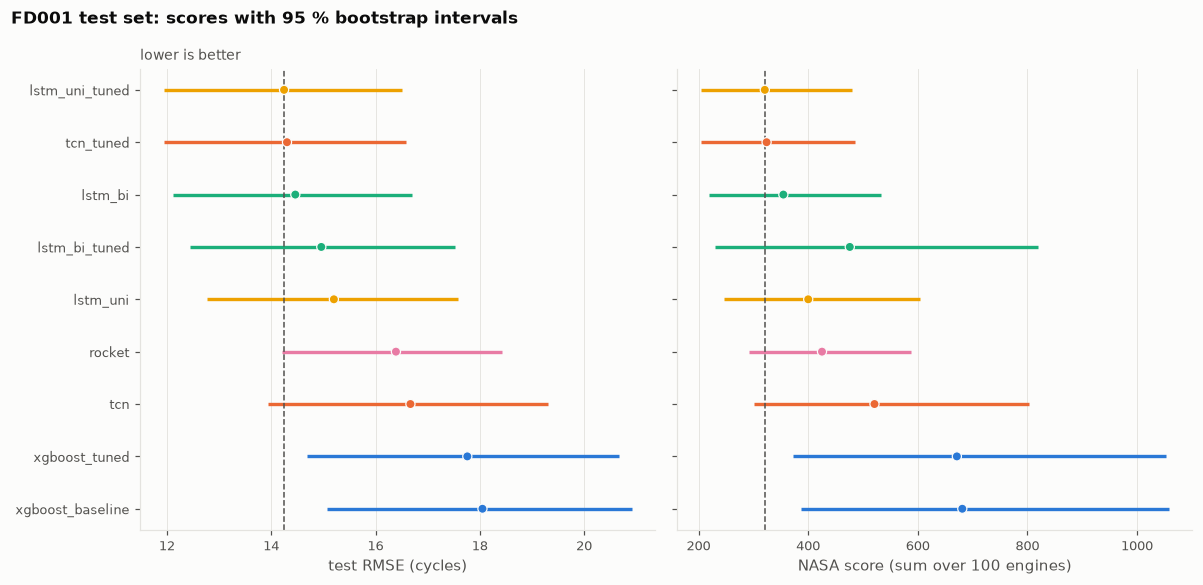

In [3]:
fig = plot_metric_intervals(table.drop(index="mean_predictor (no skill)"), BEST,
                            "FD001 test set: scores with 95 % bootstrap intervals")
plt.show()

## 3 · The proper test: paired differences
> **How to read this figure:** for each model, its RMSE minus the best model's RMSE, computed on the *same* resampled
> engines each time. Bar entirely right of 0 = reliably worse; bar crossing 0 = a tie.

**What it tells us:**
- **four models tie for first:** `lstm_uni_tuned`, `tcn_tuned`, `lstm_bi`, `lstm_bi_tuned`. No single winner can be claimed;
- ROCKET, the default TCN and both XGBoost models are reliably worse. **Deep models on raw windows beat XGBoost on
  engineered features** (+3.5 RMSE, interval +1.1 to +5.8): the most robust result of the project;
- pairing is sharper than comparing separate bars: ROCKET's bar overlaps the best model's above, yet the paired test
  shows it is worse.

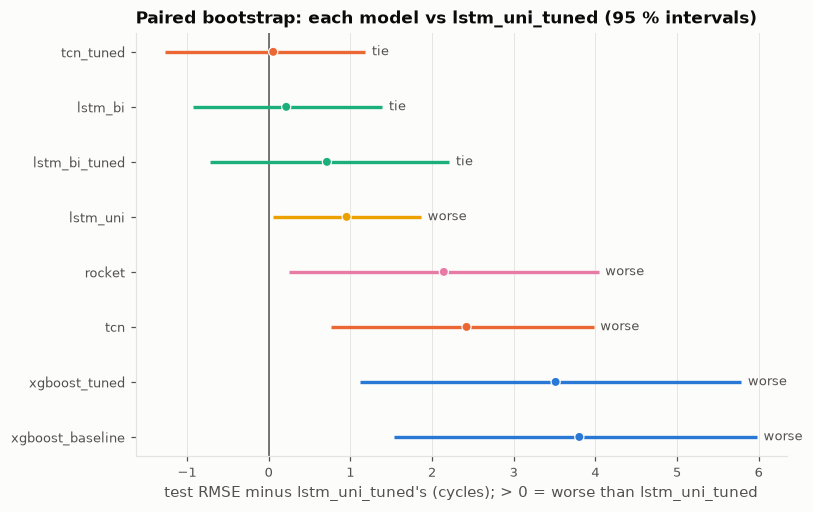

,rmse_diff,rmse_diff_ci_lo,rmse_diff_ci_hi,rmse_p_ref_better
model,,,,
xgboost_baseline,3.804,1.540,5.981,1.000
xgboost_tuned,3.514,1.120,5.789,0.998
tcn,2.424,0.763,3.981,0.998
tcn_tuned,0.056,-1.265,1.185,0.563
lstm_bi,0.216,-0.926,1.394,0.636
lstm_bi_tuned,0.714,-0.720,2.214,0.828
lstm_uni,0.955,0.054,1.868,0.982
rocket,2.145,0.251,4.042,0.987
mean_predictor (no skill),28.752,23.118,34.142,1.000


In [4]:
fig = plot_paired_differences(paired.drop(index="mean_predictor (no skill)"), BEST,
                              f"Paired bootstrap: each model vs {BEST} (95 % intervals)")
plt.show()
paired[["rmse_diff", "rmse_diff_ci_lo", "rmse_diff_ci_hi", "rmse_p_ref_better"]].round(3)

## 4 · All models over three engines' histories
> **How to read this figure:** each panel is one test engine (near failure / mid-life / healthy-ish). Every model
> predicts at every cycle of the recorded history (from cycle 30). Grey = true remaining life (not capped, so it rises
> above 125 on the left). The rightmost point is the one the test score uses. Colour = model family; solid = tuned,
> dashed = default settings.

**What it tells us:** all nine models behave almost the same — flat at the 125 cap while the engine looks healthy,
then following the decline. Their differences are mainly in the last stretch. On engine 13 (true RUL 95) every model
stays near 125 until about cycle 120: nothing in the data signals wear yet.

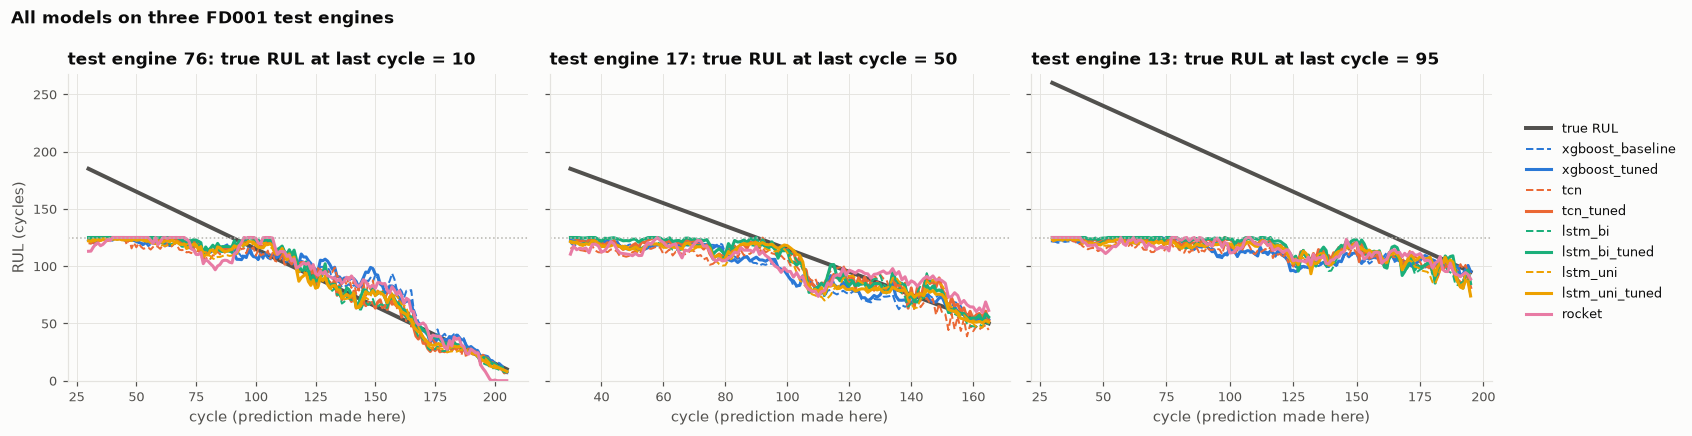

In [5]:
from src.comparison import engine_trajectory_inputs, pick_trajectory_engines, predict_kind
from src.feature_engineering import prepare_data
from src.models.loader import load_bundle
from src.plotting import plot_multi_model_trajectories
from src.registry import read_registry
d = prepare_data("FD001")
reg = read_registry()
reg = reg[reg["subset"] == "FD001"].sort_values("version").groupby("model_name").tail(1)
models = {r.model_name: load_bundle(r.path) for r in reg.itertuples()}
traj = {}
for u in pick_trajectory_engines(d):
    tin = engine_trajectory_inputs(d, u, config.SEQ_LEN)
    traj[u] = {"cycle": tin["cycle"], "truth": tin["truth"],
               "preds": {n: predict_kind(m, meta, tin) for n, (m, meta) in models.items()}}
fig = plot_multi_model_trajectories(traj, "All models on three FD001 test engines")
plt.show()

## 5 · Speed: the model alone vs the whole request
The table's latency times only `model.predict` on a prepared input (decision C5). A real request also has to turn raw
readings into model input: scaling for the deep models, but **238 rolling/lag/EMA features** for XGBoost. Below, the
API's own code path (`src/api/model_loader.py`) is timed on the 100 test engines' full histories.

**What it tells us:** XGBoost is the fastest *model* but the slowest *service*: building its features costs far more
than its prediction. The deep models need only scaling. (Inside the Docker container: 5 / 5.5 / 44 ms, EXPERIMENTS E9.)

In [6]:
import time
from src.api.model_loader import load_config, load_served_models, readings_frame
from src.data_loader import load_cmapss
served = load_served_models(load_config())
test_raw = load_cmapss("FD001", "test")
engines = [g.sort_values("cycle")[config.RAW_FEATURE_COLS].values.tolist() for _, g in test_raw.groupby("unit_id")]
rows = []
for name, m in served.items():
    m.predict_raw(readings_frame(engines[0]))                    # warm-up
    t = []
    for e in engines:
        t0 = time.perf_counter(); m.predict_raw(readings_frame(e)); t.append((time.perf_counter() - t0) * 1e3)
    rows.append({"model": name, "full request, median ms": np.median(t),
                 "model.predict only, ms (table)": table.loc[name, "latency_single_ms"]})
pd.DataFrame(rows).set_index("model").round(2)

,"full request, median ms","model.predict only, ms (table)"
model,,
lstm_uni_tuned,7.32,2.66
tcn_tuned,8.01,3.15
xgboost_tuned,110.68,1.27
